# probleme de classification

## Importer les packages

In [90]:
# Importer
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import keras
from keras.models import Sequential # permet de créer l'architecture reseaux neurones
from keras.layers import Dense # permet de créer une couche
import joblib

## Importer les données

#### Description des variables du jeu de données "Bank Marketing"

Ce jeu de données contient des informations issues de campagnes de marketing téléphonique réalisées par une banque portugaise. L'objectif est de prédire si un client souscrira à un dépôt à terme (`y`).

| Variable           | Type          | Description |
|--------------------|---------------|-------------|
| `age`              | Numérique     | Âge du client (en années). |
| `job`              | Catégorielle  | Profession du client (ex. : 'admin.', 'technician', 'services', etc.). |
| `marital`          | Catégorielle  | Statut marital du client (ex. : 'married', 'single', 'divorced'). |
| `education`        | Catégorielle  | Niveau d'éducation du client (ex. : 'basic.4y', 'high.school', 'university.degree'). |
| `default`          | Binaire       | Le client a-t-il un crédit en défaut ? ('yes', 'no'). |
| `housing`          | Binaire       | Le client a-t-il un prêt immobilier ? ('yes', 'no'). |
| `loan`             | Binaire       | Le client a-t-il un prêt personnel ? ('yes', 'no'). |
| `contact`          | Catégorielle  | Type de contact utilisé pour la communication ('cellular', 'telephone'). |
| `month`            | Catégorielle  | Mois du dernier contact client (ex. : 'may', 'aug', 'nov'). |
| `day_of_week`      | Catégorielle  | Jour de la semaine du dernier contact (ex. : 'mon', 'tue', ...). |
| `duration`         | Numérique     | Durée du dernier contact (en secondes). **Important : cette variable est très corrélée à la cible `y`**. |
| `campaign`         | Numérique     | Nombre de contacts effectués durant cette campagne. |
| `pdays`            | Numérique     | Nombre de jours depuis le dernier contact d'une campagne précédente (999 signifie "jamais contacté auparavant"). |
| `previous`         | Numérique     | Nombre de contacts effectués avant cette campagne. |
| `poutcome`         | Catégorielle  | Résultat de la campagne marketing précédente ('success', 'failure', 'nonexistent'). |
| `y`                | Cible (binaire) | Le client a-t-il souscrit à un dépôt à terme ? ('yes', 'no'). |


In [91]:
# Importer les données
df = pd.read_csv(r'C:\Users\edouard\Downloads\Projet IOT\DL 1-20261120T105911Z-1-001\DL 1\banking_dataset.csv')
df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,y
0,44,blue-collar,married,basic.4y,unknown,yes,no,cellular,aug,thu,210,1,999,0,nonexistent,no
1,53,technician,married,unknown,no,no,no,cellular,nov,fri,138,1,999,0,nonexistent,no
2,28,management,single,university.degree,no,yes,no,cellular,jun,thu,339,3,6,2,success,yes
3,39,services,married,high.school,no,no,no,cellular,apr,fri,185,2,999,0,nonexistent,no
4,55,retired,married,basic.4y,no,yes,no,cellular,aug,fri,137,1,3,1,success,yes


In [92]:
# rénommer la variable y
df.rename(columns = {'y': 'souscription'}, inplace = True)
df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,souscription
0,44,blue-collar,married,basic.4y,unknown,yes,no,cellular,aug,thu,210,1,999,0,nonexistent,no
1,53,technician,married,unknown,no,no,no,cellular,nov,fri,138,1,999,0,nonexistent,no
2,28,management,single,university.degree,no,yes,no,cellular,jun,thu,339,3,6,2,success,yes
3,39,services,married,high.school,no,no,no,cellular,apr,fri,185,2,999,0,nonexistent,no
4,55,retired,married,basic.4y,no,yes,no,cellular,aug,fri,137,1,3,1,success,yes


In [93]:
# dimension des données
df.shape

(41188, 16)

In [94]:
print(df.columns.tolist())

['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'souscription']


## Exploration des données

In [95]:
# Afficher les infos
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 16 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   age           41188 non-null  int64
 1   job           41188 non-null  str  
 2   marital       41188 non-null  str  
 3   education     41188 non-null  str  
 4   default       41188 non-null  str  
 5   housing       41188 non-null  str  
 6   loan          41188 non-null  str  
 7   contact       41188 non-null  str  
 8   month         41188 non-null  str  
 9   day_of_week   41188 non-null  str  
 10  duration      41188 non-null  int64
 11  campaign      41188 non-null  int64
 12  pdays         41188 non-null  int64
 13  previous      41188 non-null  int64
 14  poutcome      41188 non-null  str  
 15  souscription  41188 non-null  str  
dtypes: int64(5), str(11)
memory usage: 5.0 MB


In [96]:
# sélection les variables quantitatives
quant_data = df.select_dtypes(exclude= 'object')
# sélection les variables catégorielles
cat_data = df.select_dtypes(exclude = 'number')
cat_data.head()

,job,marital,education,default,housing,loan,contact,month,day_of_week,poutcome,souscription
0,blue-collar,married,basic.4y,unknown,yes,no,cellular,aug,thu,nonexistent,no
1,technician,married,unknown,no,no,no,cellular,nov,fri,nonexistent,no
2,management,single,university.degree,no,yes,no,cellular,jun,thu,success,yes
3,services,married,high.school,no,no,no,cellular,apr,fri,nonexistent,no
4,retired,married,basic.4y,no,yes,no,cellular,aug,fri,success,yes


In [97]:
df.describe( include='str').T

,count,unique,top,freq
job,41188,12,admin.,10422
marital,41188,4,married,24928
education,41188,8,university.degree,12168
default,41188,3,no,32588
housing,41188,3,yes,21576
loan,41188,3,no,33950
contact,41188,2,cellular,26144
month,41188,10,may,13769
day_of_week,41188,5,thu,8623
poutcome,41188,3,nonexistent,35563


In [98]:
# décrire les variable catégorielles
cat_data.describe().T

,count,unique,top,freq
job,41188,12,admin.,10422
marital,41188,4,married,24928
education,41188,8,university.degree,12168
default,41188,3,no,32588
housing,41188,3,yes,21576
loan,41188,3,no,33950
contact,41188,2,cellular,26144
month,41188,10,may,13769
day_of_week,41188,5,thu,8623
poutcome,41188,3,nonexistent,35563


In [99]:
# fonction de countplot
import plotly.express as px
def countplot_func(col):
  val = df[col].value_counts()# compter les nombres d'observations dans chaque classe
  fig = px.bar(x=val.index, y=val.values, color = val.index.astype(str))
  fig.show()

In [100]:
# visualiser les countplots
for col in cat_data.columns:
  countplot_func(col)

In [101]:
np.unique(df['job']).tolist()

['admin.',
 'blue-collar',
 'entrepreneur',
 'housemaid',
 'management',
 'retired',
 'self-employed',
 'services',
 'student',
 'technician',
 'unemployed',
 'unknown']

In [102]:
# télécharger les valeurs uniques de chaque variable catégorielle en utilisant joblib
import joblib as jb
uniques  = [] # [list_classe_job, list_classe_marital, .................]
for col in cat_data.columns:
  uniques.append(np.unique(df[col]).tolist())
# sauvegarder la liste uniques
jb.dump(uniques, 'uniques.joblib')

['uniques.joblib']

In [103]:
# décrire les variables quantitatives
quant_data.describe().T

,count,mean,std,min,25%,50%,75%,max
age,41188.0,40.024060,10.421250,17.0,32.0,38.0,47.0,98.0
duration,41188.0,258.285010,259.279249,0.0,102.0,180.0,319.0,4918.0
campaign,41188.0,2.567593,2.770014,1.0,1.0,2.0,3.0,56.0
pdays,41188.0,962.475454,186.910907,0.0,999.0,999.0,999.0,999.0
previous,41188.0,0.172963,0.494901,0.0,0.0,0.0,0.0,7.0


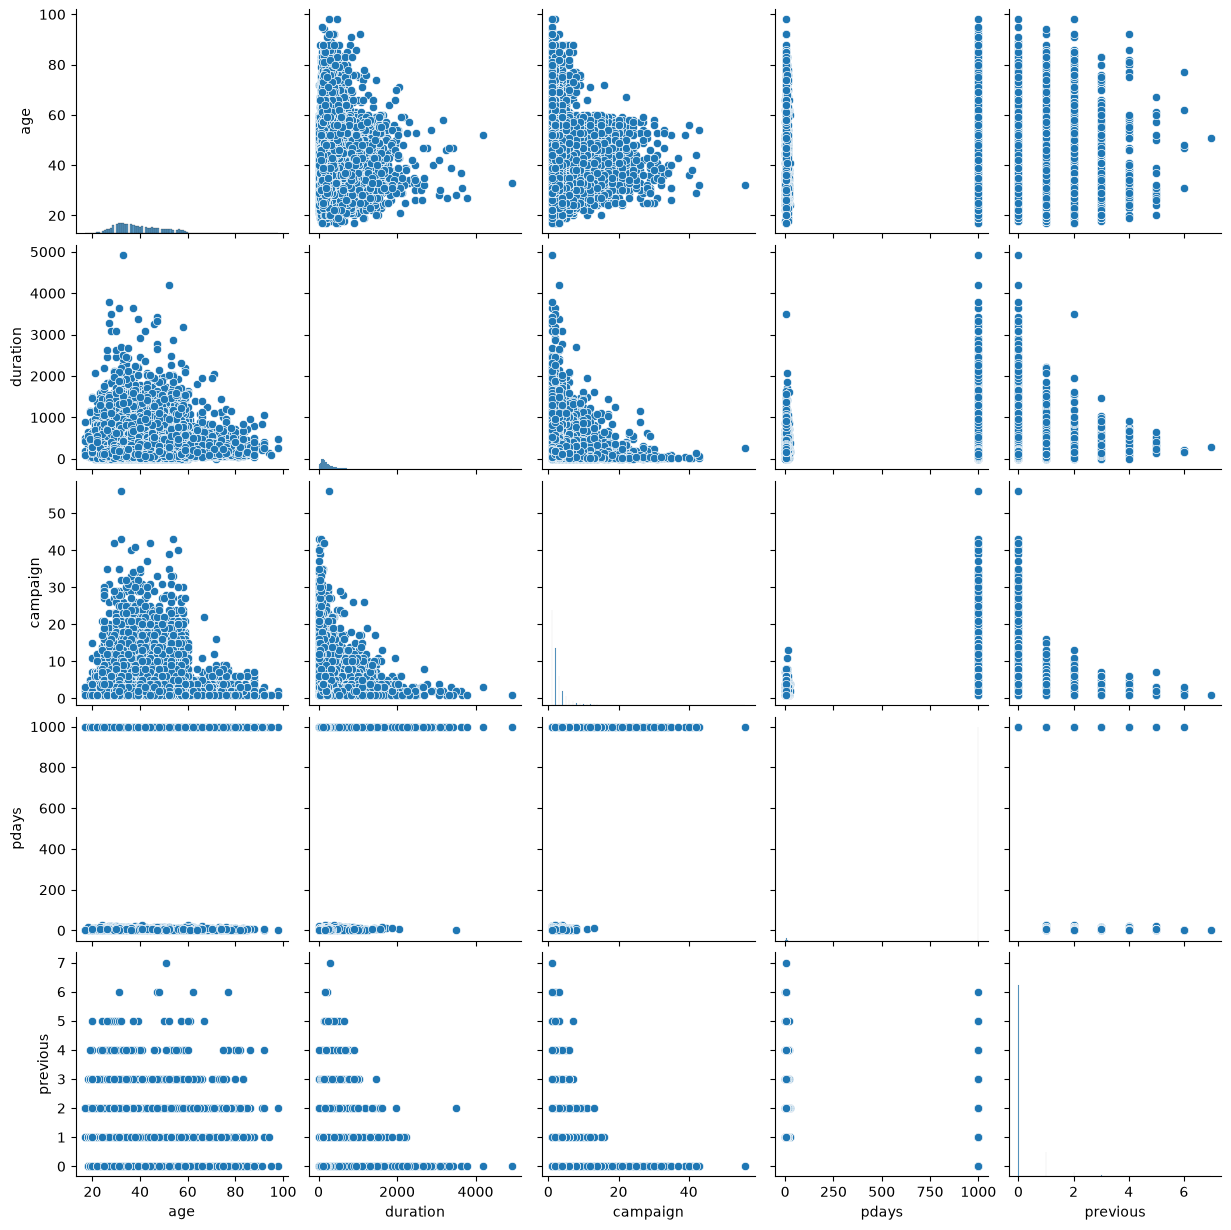

In [104]:
# pairplot des données
sns.pairplot(quant_data)
plt.show()

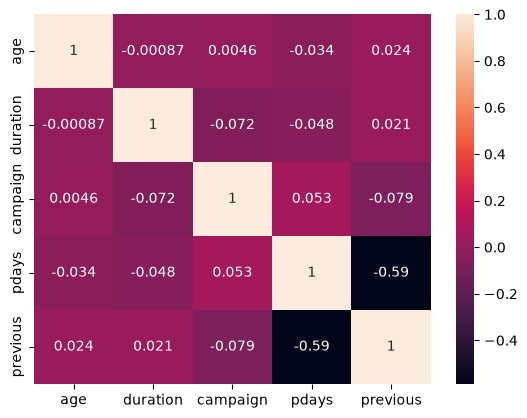

In [105]:
# matrice corrélation
sns.heatmap(quant_data.corr(), annot= True )
plt.show()

In [106]:
# fonction boxplots
def boxplot_func(col):
  plt.figure(figsize=(25,3))
  sns.boxplot(x=df[col])
  plt.show()

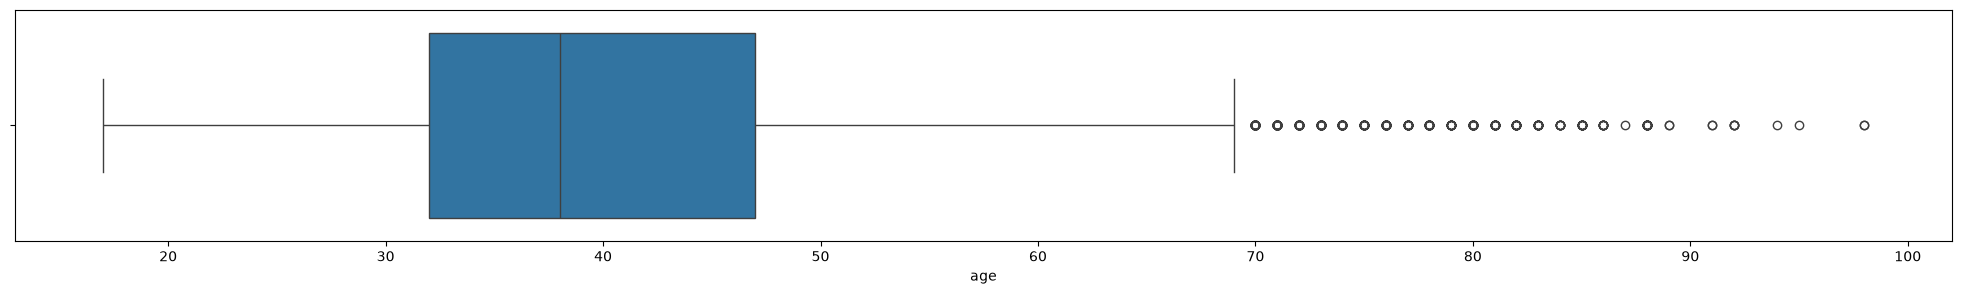

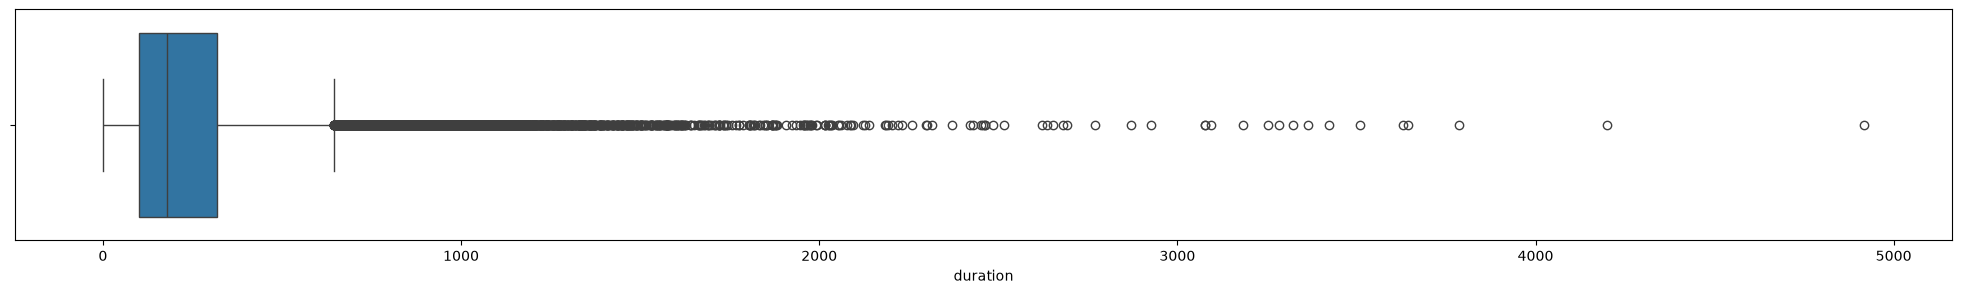

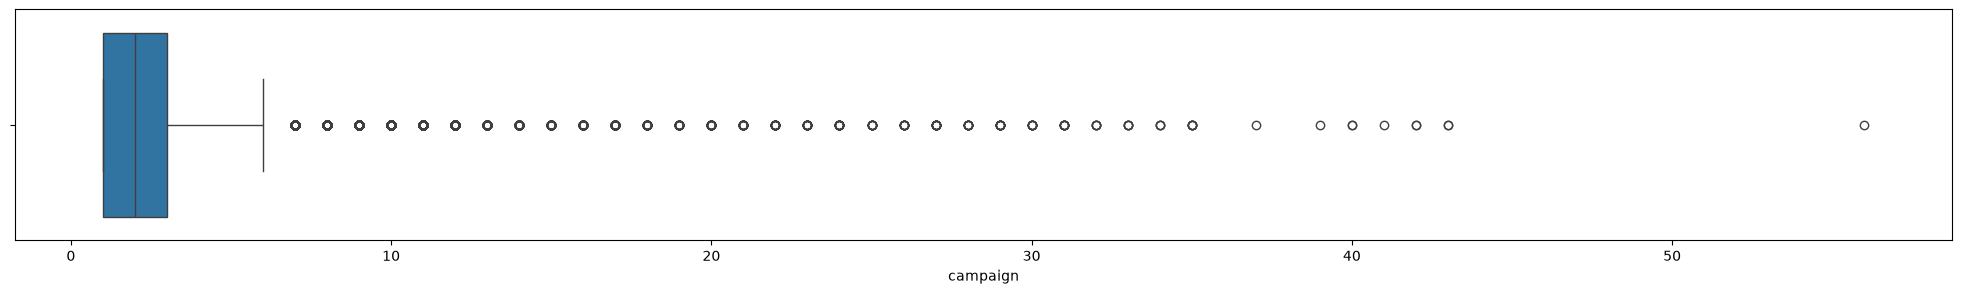

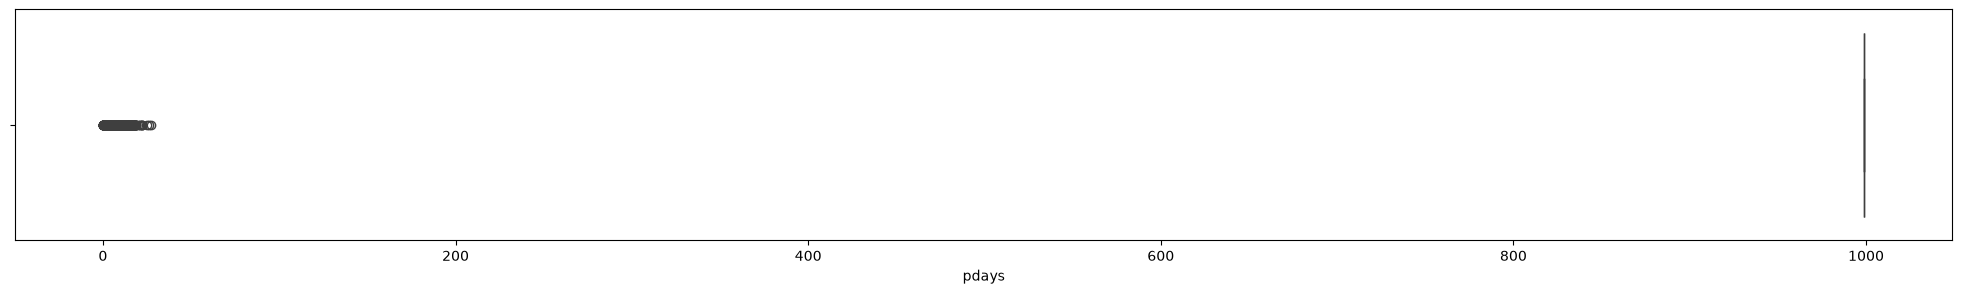

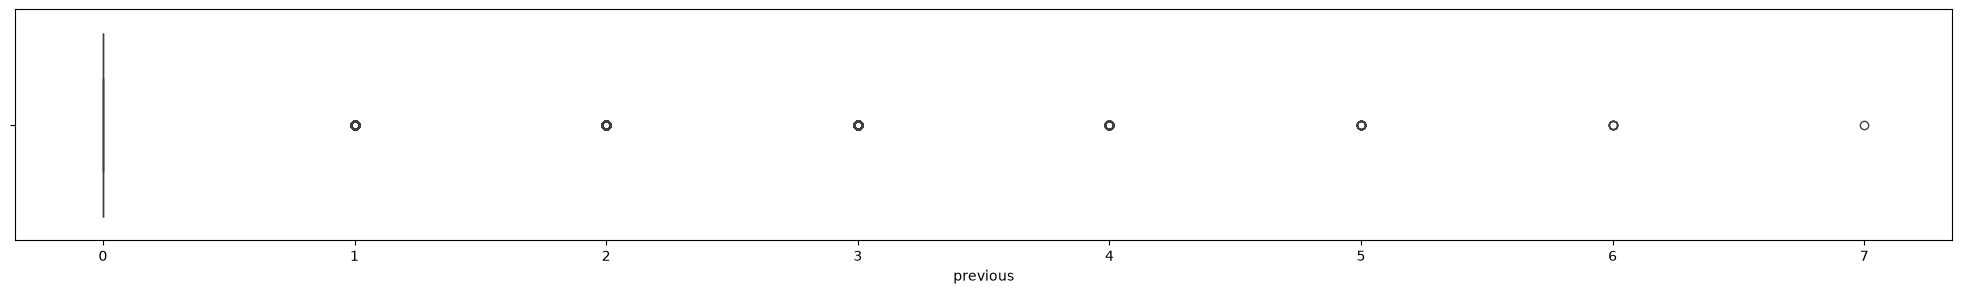

In [107]:
# boxplots des toutes les variables quantitatives
for col in quant_data.columns:
  boxplot_func(col)

## Préparation des données

In [108]:
# Encoder les variables catégorielles
from sklearn.preprocessing import LabelEncoder
encoders = []
for col in cat_data.columns:
  encoder = LabelEncoder()
  encoder.fit(df[col])
  df[col] = encoder.transform(df[col])
  encoders.append(encoder)
df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,souscription
0,44,1,1,0,1,2,0,0,1,2,210,1,999,0,1,0
1,53,9,1,7,0,0,0,0,7,0,138,1,999,0,1,0
2,28,4,2,6,0,2,0,0,4,2,339,3,6,2,2,1
3,39,7,1,3,0,0,0,0,0,0,185,2,999,0,1,0
4,55,5,1,0,0,2,0,0,1,0,137,1,3,1,2,1


In [109]:
# sauvegarde des encodeurs
jb.dump(encoders, 'encoders.joblib')

['encoders.joblib']

In [110]:
from sklearn.impute import KNNImputer
# Fonction d'imputation des valeurs aberrantes en utilisant le modèle KNN
def imputation_func(df, col, n_neighbors=5):
    # 2. Détection des outliers (Méthode IQR)
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    min_value = Q1 - 1.5 * IQR
    max_value = Q3 + 1.5 * IQR

    # Les valeurs hors bornes deviennent des valeurs manquantes pour le KNNImputer
    df.loc[(df[col] < min_value) | (df[col] > max_value), col] = np.nan
    # n_neighbors : nombre de voisins pour calculer la moyenne de remplacement
    imputer = KNNImputer(n_neighbors=n_neighbors)
    df[:] = imputer.fit_transform(df)

In [111]:
# imputer les valeurs aberrantes sur les variables  (age, duration, campaign )
for col in quant_data.columns[:-2]:
    imputation_func(df,col)

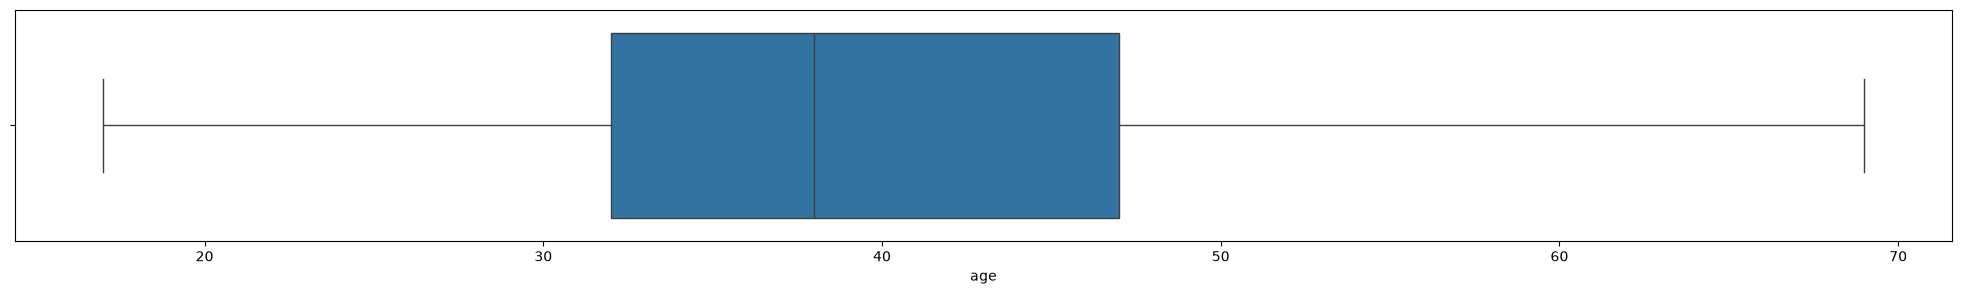

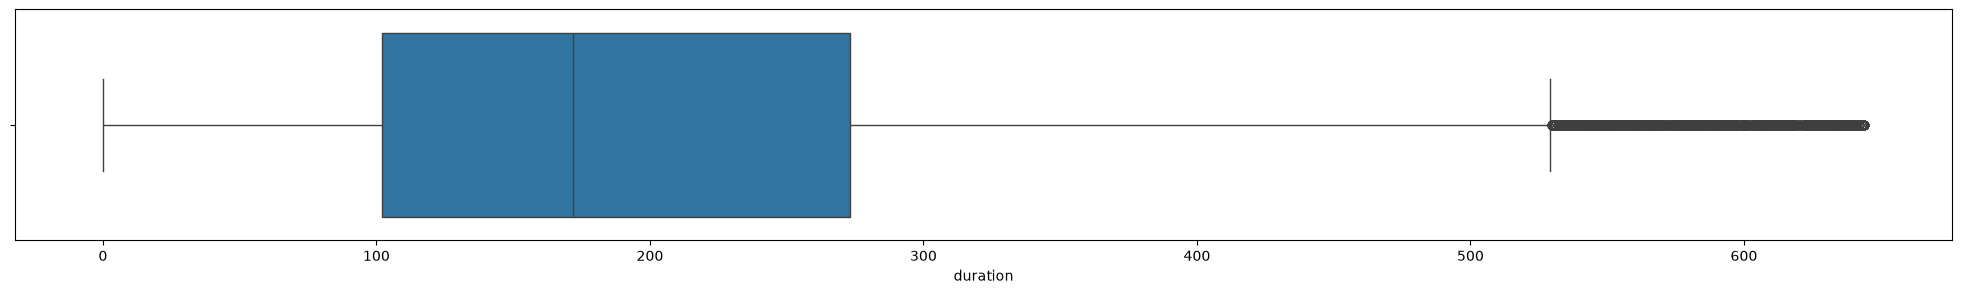

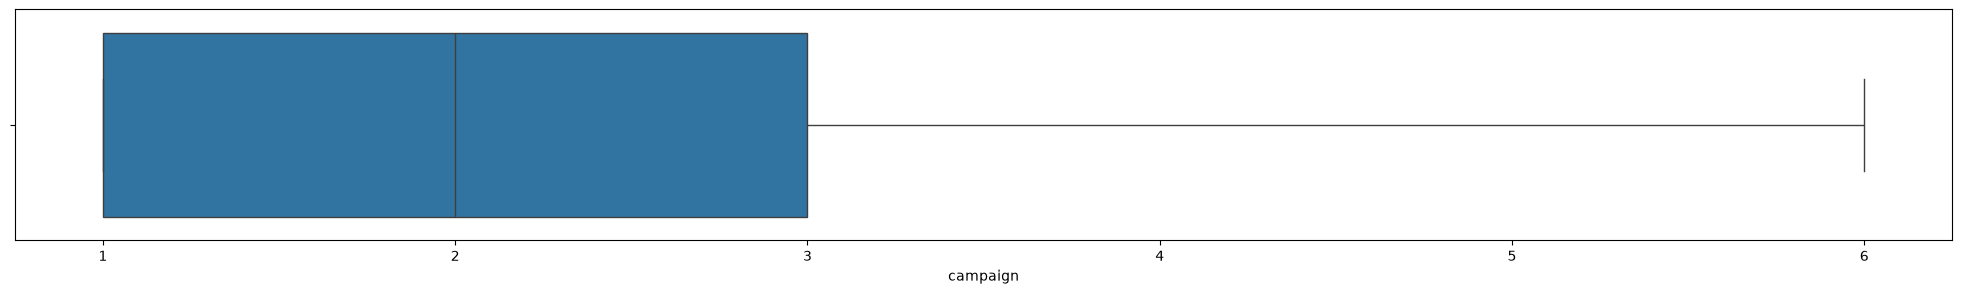

In [112]:
# réafficher les boxplots
for col in quant_data.columns[:-2]:
  boxplot_func(col)

In [113]:
# Fractionner les données en var entee et sortie
x = df.drop('souscription', axis = 1).values
y = df.souscription.values
x[:5],y[:5]

(array([[ 44.,   1.,   1.,   0.,   1.,   2.,   0.,   0.,   1.,   2., 210.,
           1., 999.,   0.,   1.],
        [ 53.,   9.,   1.,   7.,   0.,   0.,   0.,   0.,   7.,   0., 138.,
           1., 999.,   0.,   1.],
        [ 28.,   4.,   2.,   6.,   0.,   2.,   0.,   0.,   4.,   2., 339.,
           3.,   6.,   2.,   2.],
        [ 39.,   7.,   1.,   3.,   0.,   0.,   0.,   0.,   0.,   0., 185.,
           2., 999.,   0.,   1.],
        [ 55.,   5.,   1.,   0.,   0.,   2.,   0.,   0.,   1.,   0., 137.,
           1.,   3.,   1.,   2.]]),
 array([0, 0, 1, 0, 1]))

In [114]:
# Normaliser les données
from sklearn.preprocessing import RobustScaler
scaler = RobustScaler()
scaler.fit(x)
x = scaler.transform(x)
# sauvegarder le scaler
jb.dump(scaler, 'scaler.joblib')

['scaler.joblib']

In [115]:
# Splitter les données
from sklearn.model_selection import train_test_split
x_train, x_vt ,y_train, y_vt = train_test_split(x, y, test_size = 0.2, random_state = 42)
x_val, x_test, y_val, y_test = train_test_split(x_vt, y_vt, test_size = 0.5, random_state = 42)

### Modélisation

In [1]:
#Choisir le nombre de neurones optimal pour les couches cachées entre 32 et 512

In [2]:
# Afficher les paramètres optimaux

In [116]:
# Définir le modèle DNN   // ex0 du prof rechercher les parametres optimum
model = Sequential([
     #couche d'entrée avec 64 neurones et relu comme fonction d'activation
     Dense(units=64, activation = 'relu', input_shape = (x_train.shape[1], )),
     # première couche caché avec 128 neurones et relu comme fonction d'activation
     Dense(units=128, activation = 'relu'),
     # deuxième couche caché avec 256 neurones et relu comme fonction d'activation
     Dense(units=256, activation = 'relu'),
     # couche de sortie 1 neurone et sigmoid comme fonction d'activation
     Dense(units=1, activation = 'sigmoid')
     ])

# compiler le modèle
model.compile(loss= 'binary_crossentropy',optimizer='adam',metrics = ['accuracy'])
# Entrainer le modèle
history = model.fit(x_train,y_train,validation_data =(x_val,y_val),epochs=20, batch_size = 64)

Epoch 1/20


C:\Users\edouard\AppData\Roaming\Python\Python314\site-packages\keras\src\layers\core\dense.py:97: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


515/515 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8924 - loss: 0.4442 - val_accuracy: 0.9002 - val_loss: 0.2828
Epoch 2/20
515/515 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8948 - loss: 0.2907 - val_accuracy: 0.9002 - val_loss: 0.2800
Epoch 3/20
515/515 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8954 - loss: 0.2805 - val_accuracy: 0.9002 - val_loss: 0.2786
Epoch 4/20
515/515 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8966 - loss: 0.2776 - val_accuracy: 0.9002 - val_loss: 0.2757
Epoch 5/20
515/515 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8961 - loss: 0.2757 - val_accuracy: 0.9005 - val_loss: 0.2793
Epoch 6/20
515/515 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8969 - loss: 0.2739 - val_accuracy: 0.8997 - val_loss: 0.2776
Epoch 7/20
515/515 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8977 - loss: 0.2717 - val_accuracy: 0.9002 - val_loss: 0.2767
Epoch 8/20
515/515 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8987 - loss: 0.2695 - val_accuracy: 0.9002 - val_

In [117]:
#évaluer du modèle
model.evaluate(x_test, y_test)

129/129 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8893 - loss: 0.3016


[0.3016263246536255, 0.8892934918403625]

In [118]:
# # télécharger le modèle
model.save('DNN_model.h5')
model.save('DNN_model.keras')

In [119]:
# Erreur et accuracy sur les données de validation
acc_val=model.evaluate(x_val, y_val)[1]
loss_val=model.evaluate(x_val, y_val)[0]
print (f"Accuracy : {acc_val}  ----------   Loss : {loss_val}")

129/129 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8954 - loss: 0.2828
129/129 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8954 - loss: 0.2828
Accuracy : 0.8953629732131958  ----------   Loss : 0.28284773230552673


In [120]:
# Erreur et accuracy sur les données d'entrainement
acc_train=model.evaluate(x_train, y_train)[1]
loss_train=model.evaluate(x_train, y_train)[0]
print (f"Accuracy : {acc_train}  ----------   Loss : {loss_train}")

1030/1030 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9049 - loss: 0.2445
1030/1030 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9049 - loss: 0.2445
Accuracy : 0.9048861861228943  ----------   Loss : 0.24452324211597443


In [ ]:
#history.history

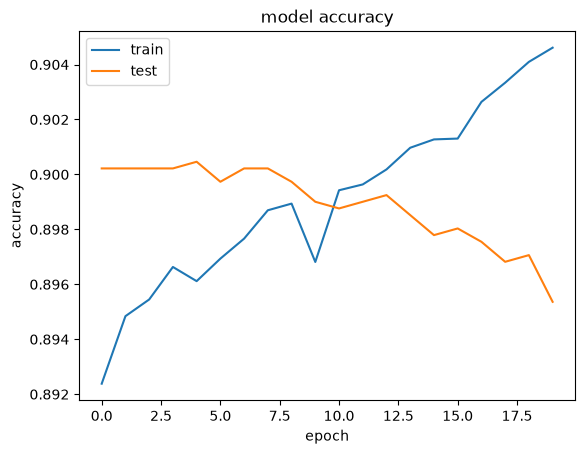

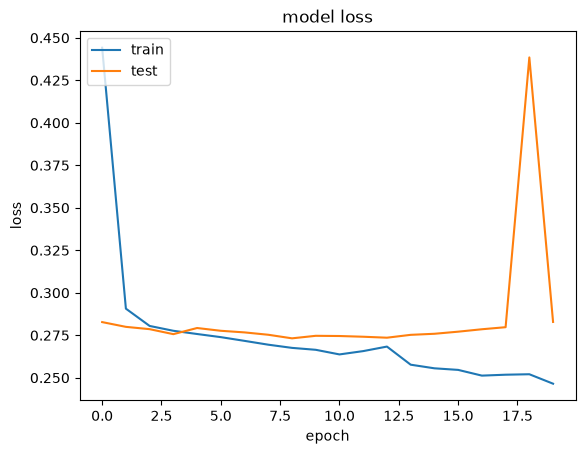

In [121]:
# plotter les accuracy et erreurs sur les données train et validation suivant les différents epochs
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'test'], loc='upper left')
plt.show()
# plotter les accuracy et erreurs sur les données train et validation suivant les différents epochs
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'test'], loc='upper left')
plt.show()

In [122]:
# faire un loading du modèle
from keras.models import load_model
model=load_model('DNN_model.keras')


In [123]:
# Tester le modèle avec quelques données test
x_test_10 = x_test [:10]
y_test_10 = y_test [:10]
#  predictions
y_pred_10 =model.predict (x_test_10)
round(y_pred_10[0][0],0)
class_names = ['pas souscrire','souscrire']
for i in range (10):
    print(f" Le client { str(i+1)} va {class_names[int (round(y_pred_10[0][0],0))]} ----------- {class_names[y_test_10[i]]}")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step
 Le client 1 va pas souscrire ----------- pas souscrire
 Le client 2 va pas souscrire ----------- pas souscrire
 Le client 3 va pas souscrire ----------- pas souscrire
 Le client 4 va pas souscrire ----------- pas souscrire
 Le client 5 va pas souscrire ----------- pas souscrire
 Le client 6 va pas souscrire ----------- pas souscrire
 Le client 7 va pas souscrire ----------- pas souscrire
 Le client 8 va pas souscrire ----------- pas souscrire
 Le client 9 va pas souscrire ----------- pas souscrire
 Le client 10 va pas souscrire ----------- pas souscrire


### Deploiment du modèle avec Gradio

In [124]:
# Fonction de prédiction
import gradio as gr
import joblib as jb
import pandas as pd
import numpy as np
# importer les encodeurs
encoders = jb.load('encoders.joblib')
# importer le modèle
model = load_model('DNN_model.h5')
# importer le scaler
scaler = jb.load('scaler.joblib')
# Fonction de prédiction simple
def prediction_func(age, job, marital, education, default, housing, loan, contact, month, day_of_week, duration, campaign, pdays, previous, poutcome):
  # encoder les valeurs
  job = encoders[0].transform([job])[0]
  marital = encoders[1].transform([marital])[0]
  education = encoders[2].transform([education])[0]
  default = encoders[3].transform([default])[0]
  housing = encoders[4].transform([housing])[0]
  loan = encoders[5].transform([loan])[0]
  contact = encoders[6].transform([contact])[0]
  month = encoders[7].transform([month])[0]
  day_of_week = encoders[8].transform([day_of_week])[0]
  poutcome = encoders[9].transform([poutcome])[0]
  # vecteur des valeurs
  x_new = np.array([age, job, marital, education, default, housing, loan, contact, month, day_of_week, duration, campaign, pdays, previous, poutcome]).reshape(1, -1)
  # normaliser les valeurs
  x_new = scaler.transform(x_new)
  # prédire la valeur
  y_pred = np.round(model.predict(x_new))
  # retourner
  if y_pred == 1:
    return 'Souscrire'
  else:
    return 'Pas souscrire'

In [125]:
# load les valeurs uniques
uniques = jb.load ('uniques.joblib')
# créer les inputs
inputs = [gr.Number(label="age"),
          gr.Dropdown(choices = uniques[0], label="job"),
          gr.Dropdown(uniques[1], label="marital"),
          gr.Dropdown(uniques[2], label="education"),
          gr.Dropdown(uniques[3], label="default"),
          gr.Dropdown(uniques[4], label="housing"),
          gr.Dropdown(uniques[5], label="loan"),
          gr.Dropdown(uniques[6], label="contact"),
          gr.Dropdown(uniques[7], label="month"),
          gr.Dropdown(uniques[8], label="day_of_week"),
          gr.Number(label="duration"),
          gr.Number(label="campaign"),
          gr.Number(label="pdays"),
          gr.Number(label="previous"),
          gr.Dropdown(uniques[9], label="poutcome")]
# créer les outputs
outputs = gr.Textbox(label = 'Souscription')
# Interface
Interface =gr.Interface(fn = prediction_func,
             inputs = inputs,
             outputs = outputs,
             title = 'Bank Marketing Prediction')
Interface.launch()

* Running on local URL:  http://127.0.0.1:7861
* To create a public link, set `share=True` in `launch()`.


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
